In [15]:
import os
from dotenv import load_dotenv
from pydantic import BaseModel, Field
from langgraph.graph import StateGraph,START,END
from typing import TypedDict , Literal ,Annotated
from langchain_huggingface import HuggingFaceEmbeddings, HuggingFaceEndpoint,ChatHuggingFace
from langchain_core.messages import SystemMessage, HumanMessage 



In [16]:
load_dotenv()

HF_TOKEN = os.getenv("HF_TOKEN")
HUGGINGFACE_REPO_ID = "Qwen/Qwen2.5-7B-Instruct"

if not HF_TOKEN:
    raise ValueError("HF_TOKEN is missing. Add it to your .env file or environment variables.")

In [17]:
generator_llm = HuggingFaceEndpoint(
    repo_id="Qwen/Qwen3-4B",
    task="text-generation",
    provider="featherless-ai",
    huggingfacehub_api_token=HF_TOKEN,
    temperature=0.5,
)

evaluator_llm = HuggingFaceEndpoint(
    repo_id="prometheus-eval/prometheus-7b-v2.0",
    task="text-generation",
    provider="featherless-ai",
    huggingfacehub_api_token=HF_TOKEN,
    temperature=0.5,
)

optimise_llm = HuggingFaceEndpoint(
    repo_id="Qwen/Qwen3-4B",
    task="text-generation",
    provider="featherless-ai",
    huggingfacehub_api_token=HF_TOKEN,
    temperature=0.5,
)

generator_llm_model = ChatHuggingFace(llm=generator_llm, verbose=True)
evaluator_llm_model = ChatHuggingFace(llm=evaluator_llm, verbose=True)
optimise_llm_model = ChatHuggingFace(llm=optimise_llm, verbose=True)

In [18]:
%pip install -U langchain-google-genai

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.2.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [19]:
%pip install -U langchain-google-genai

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.2.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [20]:
from pydantic import BaseModel, Field

class TweetEvaluation(BaseModel):
    evaluation: Literal["approved", "needs_improvement"] = Field(..., description="Final evaluation result.")
    feedback: str = Field(..., description="feedback for the tweet.")

In [21]:
structured_evaluator_llm_model = evaluator_llm_model.with_structured_output(
    TweetEvaluation,
    method="json_schema",
)

In [22]:
class TweetState(TypedDict):
    topic: str
    tweet: str
    evaluation: Literal["approved","rejected"]
    feedback: str
    iteration: int
    max_iteration: int

In [23]:
def generate_tweet(state: TweetState):
    # prompt
    messages = [
        SystemMessage(content="You are a funny and clever Twitter/X influencer."),
        HumanMessage(content=f"""
                                    Write a short, original, and hilarious tweet on the topic: "{state['topic']}".

                                    Rules:
                                    - Do NOT use question-answer format.
                                    - Max 280 characters.
                                    - Use observational humor, irony, sarcasm, or cultural references.
                                    - Think in meme logic, punchlines, or relatable takes.
                                    - Use simple, day to day english
                                """
                    )
                ]
    
    # generate llm
    
    response = generator_llm_model.invoke(messages).content

    # output return response 

    return{'Tweet':response}


 

    
# def optimise_tweet(state: TweetState):

In [24]:
def evaluate_tweet(state: TweetState):

     # prompt
    messages = [
                    SystemMessage(content="You are a ruthless, no-laugh-given Twitter critic. You evaluate tweets based on humor, originality, virality, and tweet format."),
                    HumanMessage(content=f"""
                                                Evaluate the following tweet:

                                                Tweet: "{state['tweet']}"

                                                Use the criteria below to evaluate the tweet:

                                                1. Originality – Is this fresh, or have you seen it a hundred times before?  
                                                2. Humor – Did it genuinely make you smile, laugh, or chuckle?  
                                                3. Punchiness – Is it short, sharp, and scroll-stopping?  
                                                4. Virality Potential – Would people retweet or share it?  
                                                5. Format – Is it a well-formed tweet (not a setup-punchline joke, not a Q&A joke, and under 280 characters)?

                                                Auto-reject if:
                                                - It's written in question-answer format (e.g., "Why did..." or "What happens when...")
                                                - It exceeds 280 characters
                                                - It reads like a traditional setup-punchline joke
                                                - Dont end with generic, throwaway, or deflating lines that weaken the humor (e.g., “Masterpieces of the auntie-uncle universe” or vague summaries)

                                                ### Respond ONLY in structured format:
                                                - evaluation: "approved" or "needs_improvement"  
                                                - feedback: One paragraph explaining the strengths and weaknesses 
                                            """)

    ]
    # evaluate llm 
    response = structured_evaluator_llm_model.invoke(messages)     

    # return response
    return {'evaluation':response.evaluation,'feedback':response.feedback}                                   
                

In [25]:
def optimise_tweet (state: TweetState):

    # prompt
    
    messages = [
        SystemMessage(content="You punch up tweets for virality and humor based on given feedback."),
        HumanMessage(content=f"""
                                    Improve the tweet based on this feedback:
                                    "{state['feedback']}"

                                    Topic: "{state['topic']}"
                                    Original Tweet:
                                    {state['tweet']}

                                    Re-write it as a short, viral-worthy tweet. Avoid Q&A style and stay under 280 characters.
                                """)
                ]
    # optimise tweet
    response = optimise_llm.invoke(messages).content
    iteration=state['iteration']+1

    # return output
    return {'tweet': response, 'iteration': iteration}

In [26]:
def route_evolution(state: TweetState):
    if(state['evaluation']=='approved' or state['iteration']>=state['max_iteration']):
        return 'approved'
    else:
        return 'needs_improvement'

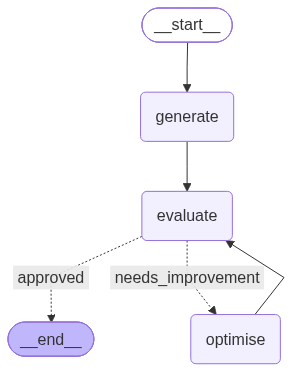

In [27]:
graph=StateGraph(TweetState)
graph.add_node('generate', generate_tweet)
graph.add_node('evaluate', evaluate_tweet)
graph.add_node('optimise', optimise_tweet)

graph.add_edge(START,'generate')
graph.add_edge('generate','evaluate')

graph.add_conditional_edges('evaluate',route_evolution , {'approved': END ,'needs_improvement':'optimise'})
graph.add_edge('optimise','evaluate')


workflow=graph.compile()
workflow


In [28]:
initial_state={
    "topic":"Indian Railways",
    "iteration":1,
    "max_iteration":5
}

workflow.invoke(initial_state)

HfHubHTTPError: Client error '402 Payment Required' for url 'https://router.huggingface.co/featherless-ai/v1/chat/completions' (Request ID: Root=1-6ae49e71-73c905e704c9602704e38536;8493ce72-7db3-4983-92a8-e7787dcae336)
For more information check: https://developer.mozilla.org/en-US/docs/Web/HTTP/Status/402

You have no remaining credits. Purchase pre-paid credits to continue using Inference Providers. Alternatively, subscribe to PRO to get monthly included credits.